# Camuflaj digital termic — prototip pentru prezentarea preliminară

**Grigoraș Ioana-Daria · Moscalu Ionela-Georgiana · grupa 1307B**

Acest notebook arată experimentul pregătit pentru următoarea ascultare: încărcăm datele,
afișăm adnotările, rulăm un detector existent, modificăm regiunile persoanelor prin Telea
și comparăm detecțiile înainte și după modificare.

**Stadiu:** prototip preliminar, cu un detector YOLOv8n preantrenat pe COCO și o metodă
de procesare. Lotul demonstrativ are 12 imagini din `train`, selectate cu seed 42.
Antrenarea pe termic și evaluarea finală pe `test` sunt etape ulterioare.

## Cum îl folosim în Colab

1. Deschidem acest fișier și conectăm o sesiune Python. Codul folosește CPU; GPU nu este necesar.
2. Rulăm celulele în ordine, de sus în jos. Descărcarea inițială a datelor și a modelului necesită internet.
3. La export se descarcă arhiva rezultatelor. Așteptăm încheierea celulelor de evaluare pentru tabelul final.
4. Salvăm notebook-ul după rulare și păstrăm arhiva și PPT-ul pentru prezentare.

**Despre ieșirile afișate:** graficele și rezultatele existente provin din rularea noastră.
Celulele adăugate pentru scrierea evaluatorului și tabelul final trebuie executate în Colab.
Versiunea datasetului și versiunea Ultralytics sunt fixate la cele din experimentul păstrat;
ceilalți parametri și pașii de procesare rămân cei folosiți de noi.

## 1. Instalarea bibliotecilor și descărcarea datelor

Folosim datasetul [Thermal Images for Human Detection](https://www.kaggle.com/datasets/sikdermdsaiful/thermal-images-for-human-detection),
versiunea 1. `kagglehub` îl descarcă; `Pillow` citește imaginile.


In [ ]:
%pip install -q kagglehub pillow

In [ ]:
from pathlib import Path
import kagglehub

dataset_path = Path(
    kagglehub.dataset_download(
        "sikdermdsaiful/thermal-images-for-human-detection/versions/1"
    )
)

print("Datasetul este în:")
print(dataset_path)

100%|██████████| 1.28G/1.28G [00:37<00:00, 37.0MB/s]

Extracting files...


Datasetul este în:
/root/.cache/kagglehub/datasets/sikdermdsaiful/thermal-images-for-human-detection/versions/1


## 2. Verificarea structurii datasetului

Identificăm directorul care conține `train` și `test`. În rularea păstrată apar
12.023 de imagini și 12.023 de fișiere de etichete în `train`, respectiv 3.463 și 3.463 în `test`.

Această celulă verifică existența directoarelor și numără fișierele. Validarea completă
a tuturor perechilor imagine–etichetă și a tuturor adnotărilor rămâne o sarcină separată.


In [ ]:
ROOT = dataset_path / "dataset"

if not ROOT.is_dir():
    ROOT = dataset_path

print("Directorul principal:", ROOT)

for split in ["train", "test"]:
    for tip in ["images", "labels"]:
        folder = ROOT / split / tip

        if not folder.is_dir():
            raise FileNotFoundError(f"Lipsește directorul: {folder}")

        numar = sum(f.is_file() for f in folder.iterdir())

        print(f"{split}/{tip}: {numar} fișiere")

Directorul principal: /root/.cache/kagglehub/datasets/sikdermdsaiful/thermal-images-for-human-detection/versions/1/dataset
train/images: 12023 fișiere
train/labels: 12023 fișiere
test/images: 3463 fișiere
test/labels: 3463 fișiere


## 3. Citirea unei imagini și a adnotărilor YOLO

Prima imagine, `010001.jpg`, servește pentru demonstrația pe un singur exemplu.
Un rând de etichetă are forma `clasa xc yc bw bh`, cu poziții și dimensiuni normalizate.
În acest experiment păstrăm clasa `0`, persoană.

Convertim adnotările în pixeli folosind lățimea `W` și înălțimea `H`:

$$
x_1=(x_c-b_w/2)W,\quad y_1=(y_c-b_h/2)H,
\qquad x_2=(x_c+b_w/2)W,\quad y_2=(y_c+b_h/2)H.
$$

Rotunjim marginile spre exterior și le limităm la imagine. Dreptunghiurile verzi sunt
**adnotările de referință (ground truth, GT)**, nu predicțiile detectorului.


Imagine: 010001.jpg
Dimensiuni: (1280, 1024)

Adnotări:
0 0.24921875 0.5322265625 0.05 0.228515625
0 0.302734375 0.50439453125 0.05703125 0.2451171875
0 0.396875 0.47900390625 0.065625 0.2412109375
0 0.570703125 0.45849609375 0.04765625 0.2255859375
0 0.58984375 0.64013671875 0.0796875 0.2705078125
0 0.90625 0.13037109375 0.05625 0.2177734375



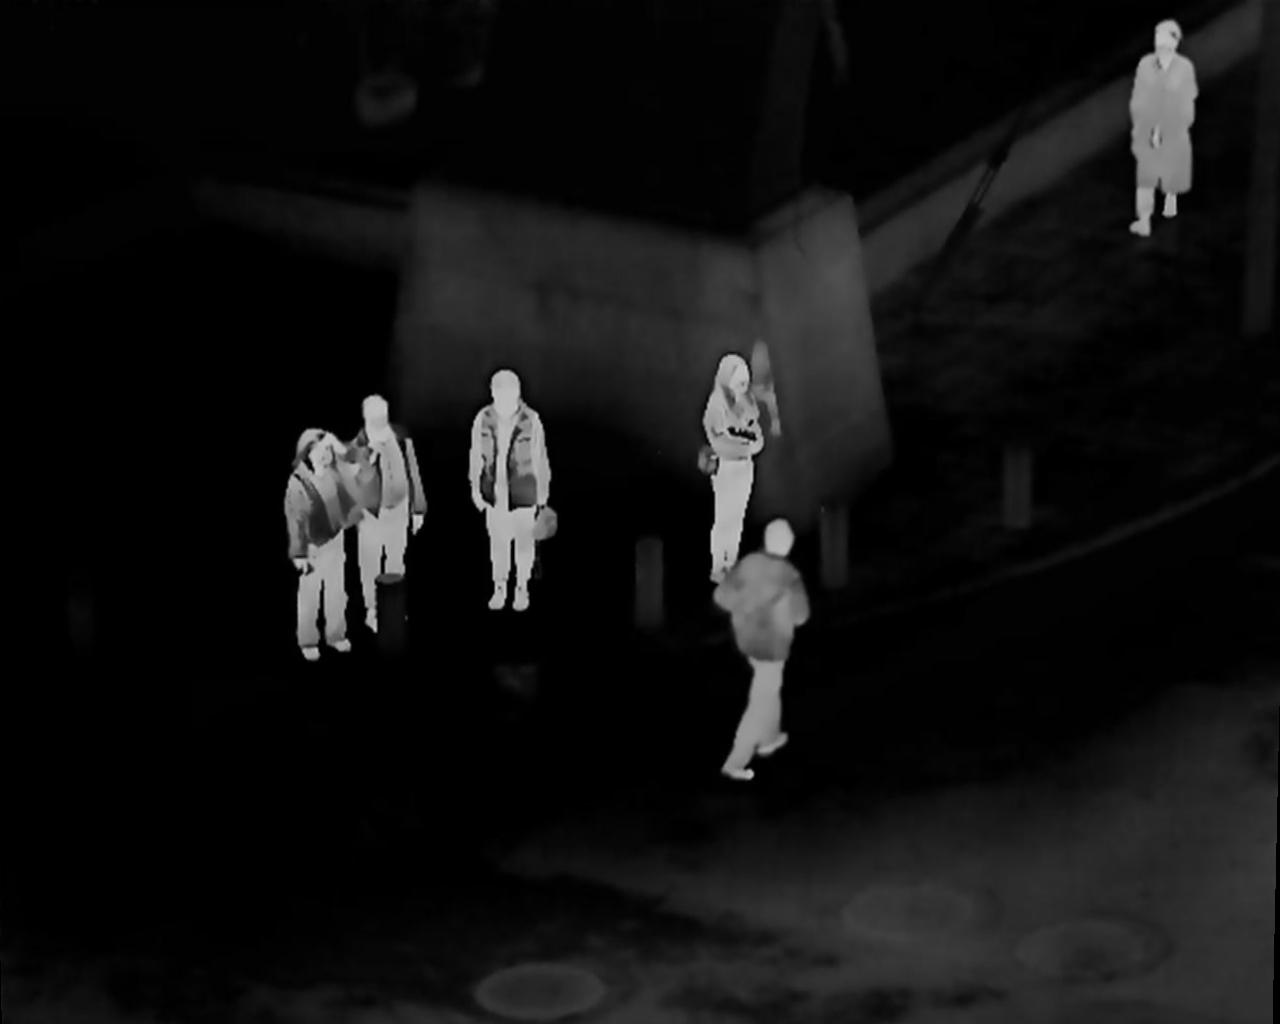

In [ ]:
from PIL import Image
from IPython.display import display

imagini = sorted((ROOT / "train" / "images").glob("*.jpg"))

if not imagini:
    raise FileNotFoundError("Nu am găsit imagini JPG în train/images.")

image_path = imagini[0]

label_path = (
    ROOT / "train" / "labels" / f"{image_path.stem}.txt"
)

imagine = Image.open(image_path)

print("Imagine:", image_path.name)
print("Dimensiuni:", imagine.size)
print("\nAdnotări:")
print(label_path.read_text())

display(imagine)


Număr de persoane adnotate: 6
Dreptunghiuri în pixeli: [(287, 428, 351, 662), (351, 391, 424, 642), (465, 367, 550, 614), (700, 354, 761, 585), (704, 517, 806, 794), (1124, 22, 1196, 245)]


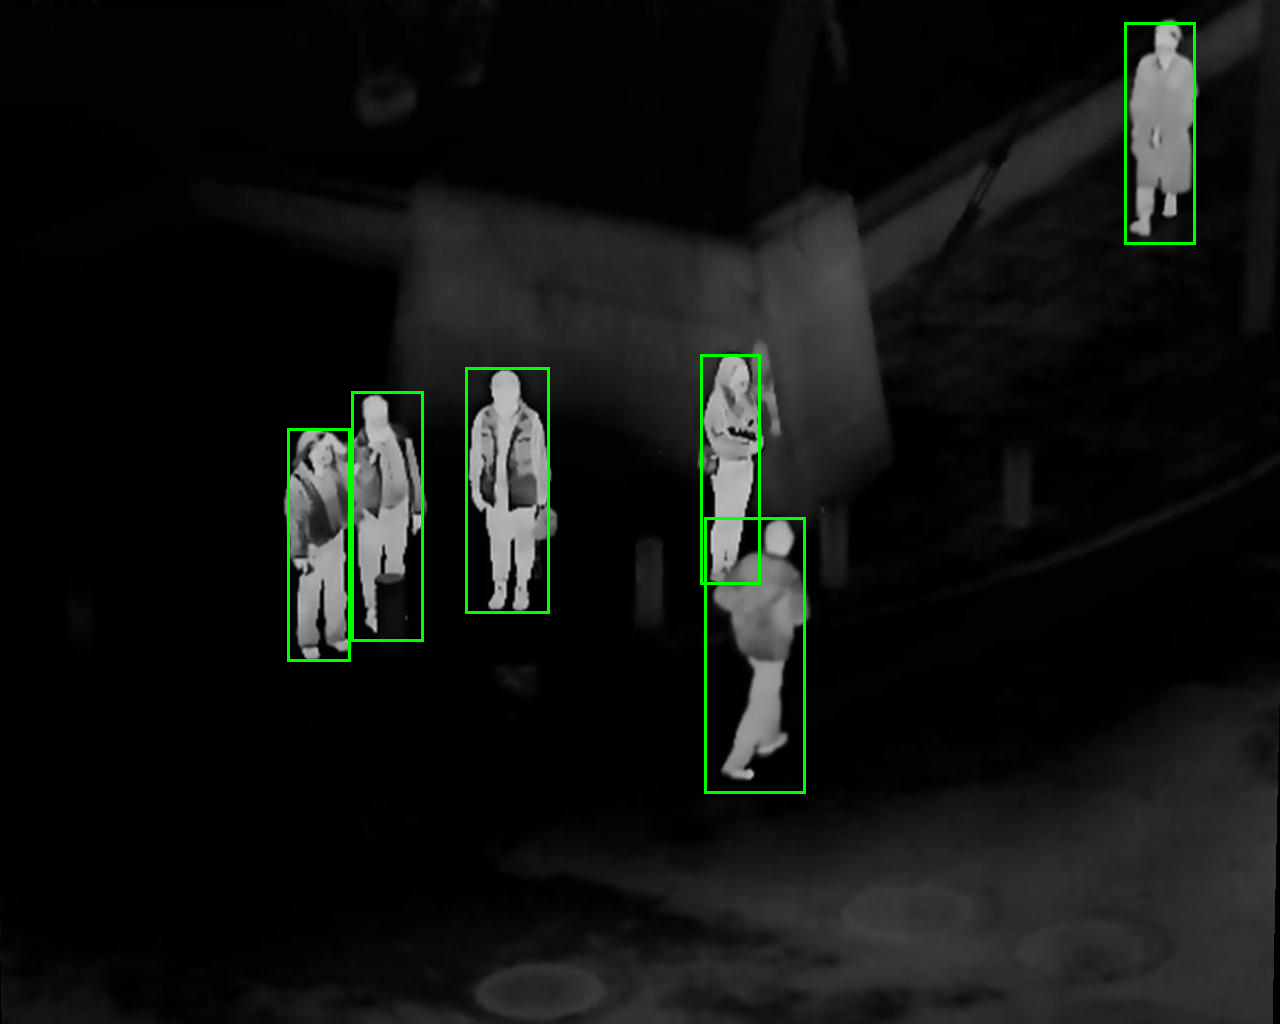

In [ ]:
import math
from PIL import ImageDraw


def citeste_bbox_yolo(cale_txt, W, H):
    boxes = []

    for linie in cale_txt.read_text().splitlines():
        if not linie.strip():
            continue

        clasa, xc, yc, bw, bh = map(float, linie.split())

        # Păstrăm clasa person.
        if clasa != 0:
            continue

        # Transformăm marginile în coordonate de pixeli.
        x1 = math.floor((xc - bw / 2) * W)
        y1 = math.floor((yc - bh / 2) * H)
        x2 = math.ceil((xc + bw / 2) * W)
        y2 = math.ceil((yc + bh / 2) * H)

        # Limităm dreptunghiul la dimensiunile imaginii.
        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(W, x2)
        y2 = min(H, y2)

        if x2 <= x1 or y2 <= y1:
            raise ValueError(f"Dreptunghi invalid: {linie}")

        boxes.append((x1, y1, x2, y2))

    return boxes


W, H = imagine.size

boxes_xyxy = citeste_bbox_yolo(label_path, W, H)

# Desenăm pe o copie, păstrând originalul.
imagine_cu_bbox = imagine.copy().convert("RGB")
desen = ImageDraw.Draw(imagine_cu_bbox)

for x1, y1, x2, y2 in boxes_xyxy:
    desen.rectangle(
        (x1, y1, x2 - 1, y2 - 1),
        outline="lime",
        width=3
    )

print("Număr de persoane adnotate:", len(boxes_xyxy))
print("Dreptunghiuri în pixeli:", boxes_xyxy)

display(imagine_cu_bbox)

## 4. Construirea măștii ROI

ROI înseamnă regiune de interes. Masca are valoarea `255` în reuniunea dreptunghiurilor
adnotate și `0` în rest. Suprapunerile sunt numărate o singură dată.

`Pillow` dă dimensiunile ca `(W, H)`, iar NumPy indexează imaginea ca `[y, x]`,
deci forma măștii este `(H, W)`. Marginile `x2` și `y2` sunt exclusive.
În prototip folosim **adnotările reale pentru mască**; detectorul nu alege regiunile modificate.


Dimensiunile măștii: (1024, 1280)
Număr de pixeli în ROI: 108819


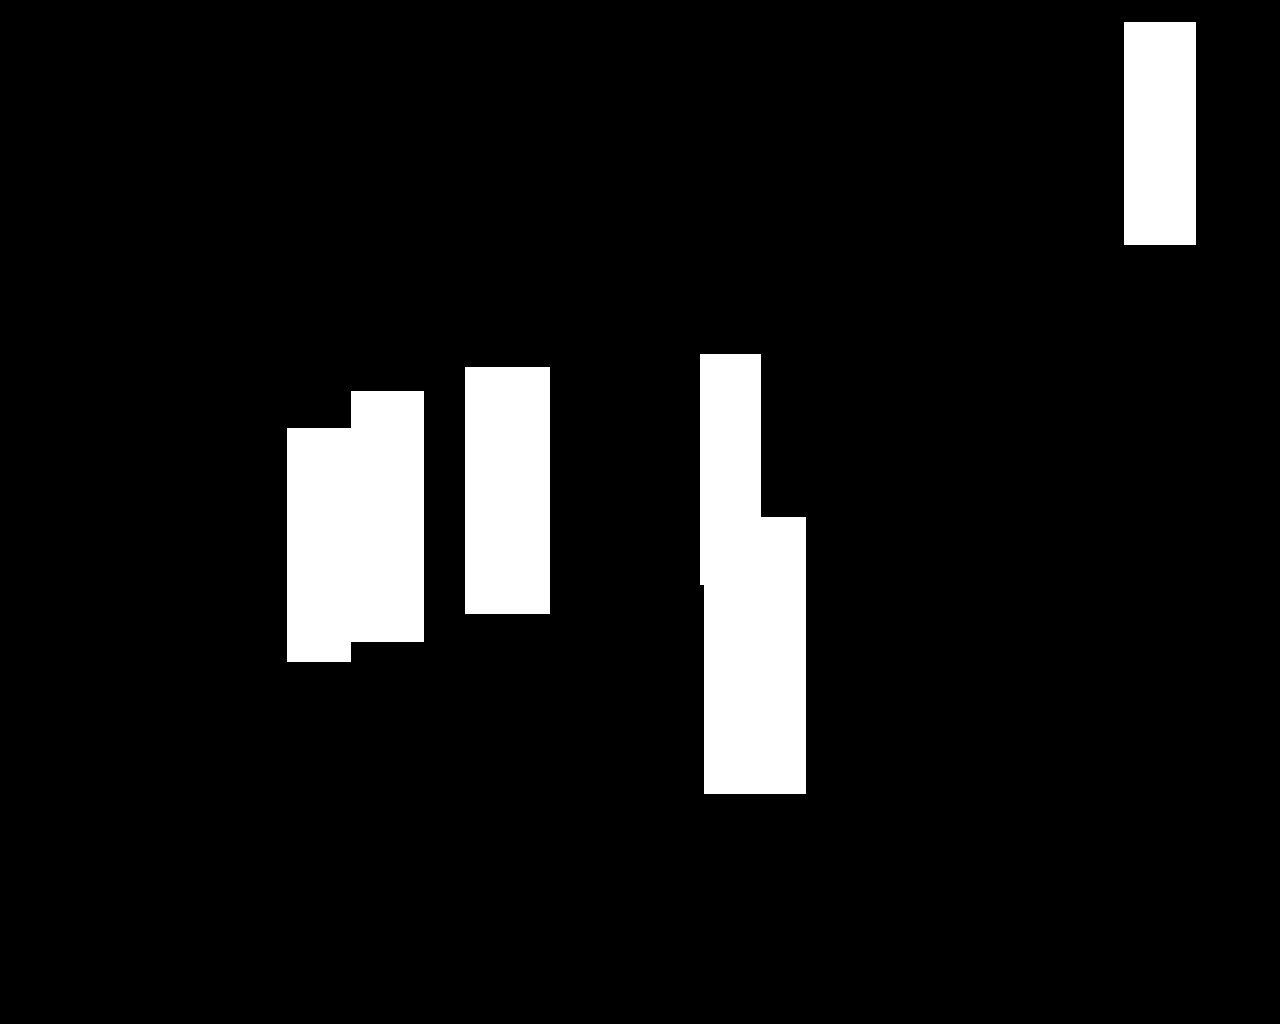

In [ ]:
import numpy as np

# NumPy folosește ordinea: înălțime, lățime.
masca = np.zeros((H, W), dtype=np.uint8)

for x1, y1, x2, y2 in boxes_xyxy:
    masca[y1:y2, x1:x2] = 255

print("Dimensiunile măștii:", masca.shape)
print("Număr de pixeli în ROI:", np.count_nonzero(masca))

display(Image.fromarray(masca))

## 5. Alegerea lotului demonstrativ

Selectăm 12 imagini din `train` cu `random.Random(42)` și le afișăm cu adnotări.
Aceeași listă `selectie` va fi folosită la procesarea în lot.
`010001.jpg`, folosită mai sus, este un exemplu separat și nu se adaugă la totalul de 12 imagini.

Acesta este un lot de dezvoltare pentru verificarea prototipului. Rezultatele lui nu reprezintă
o evaluare finală a performanței pe întregul dataset.


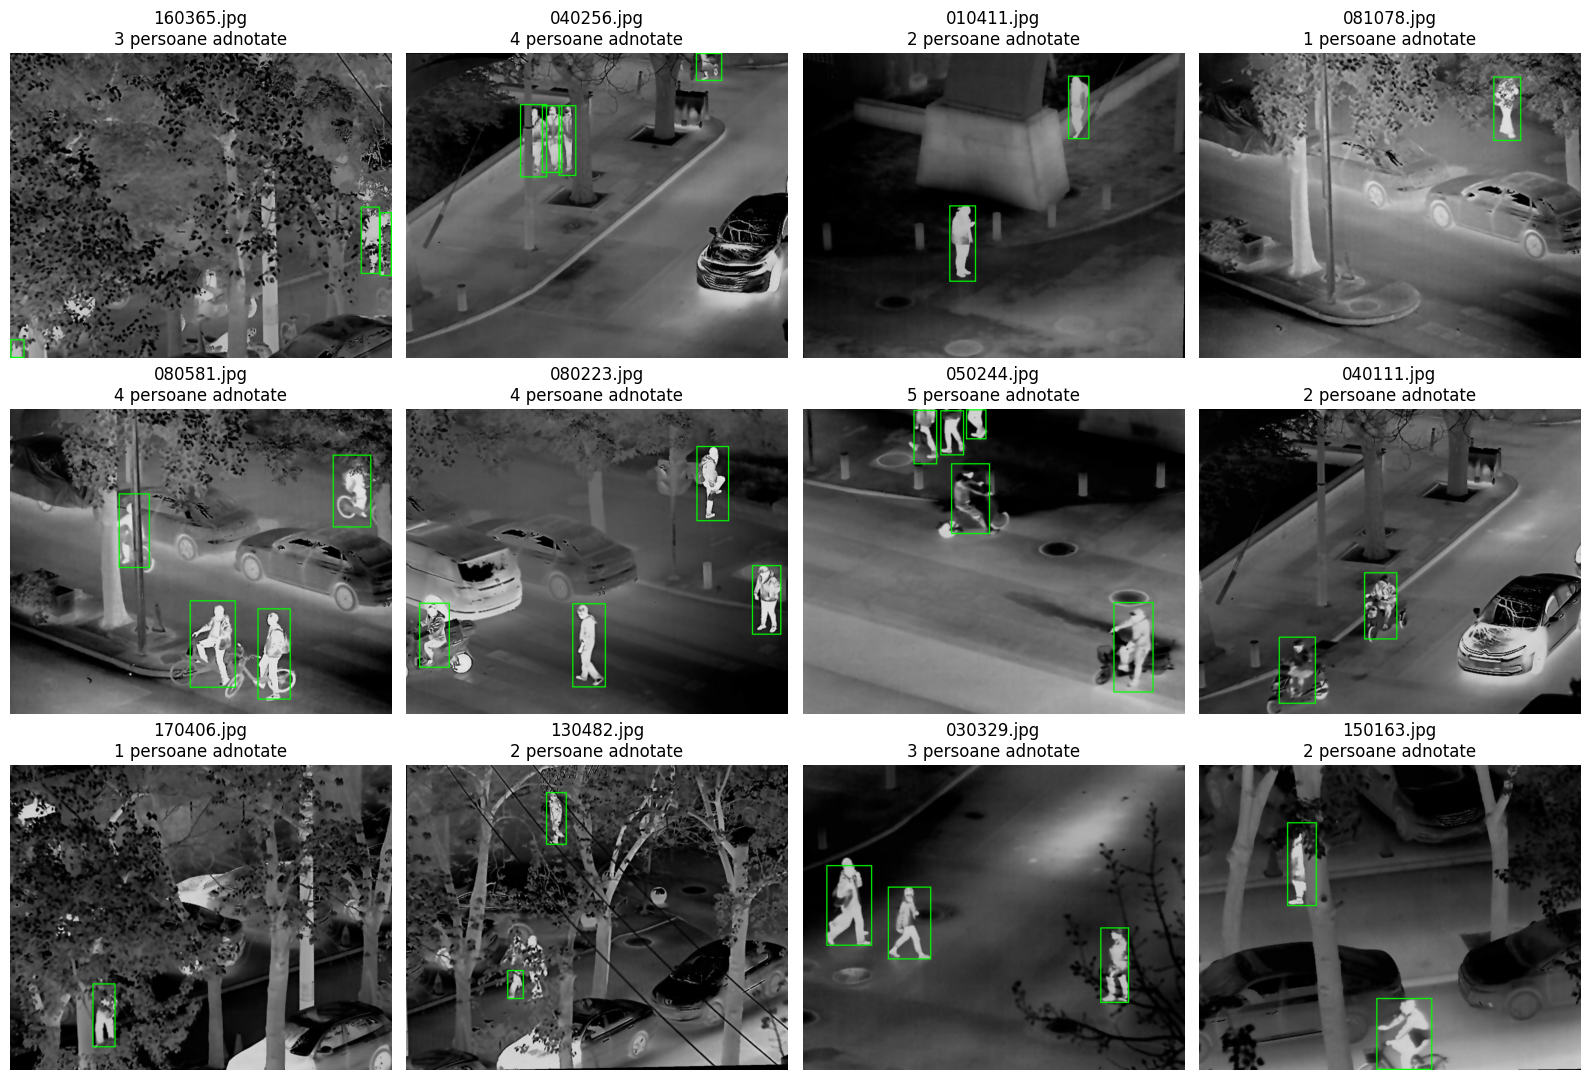

In [ ]:
import random
import matplotlib.pyplot as plt

selectie = random.Random(42).sample(
    imagini,
    min(12, len(imagini))
)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))

for ax in axes.flat:
    ax.axis("off")

for ax, cale_imagine in zip(axes.flat, selectie):
    img = Image.open(cale_imagine).convert("RGB")
    W_img, H_img = img.size

    cale_txt = (
        ROOT / "train" / "labels"
        / f"{cale_imagine.stem}.txt"
    )

    boxes_img = citeste_bbox_yolo(cale_txt, W_img, H_img)

    desen_img = ImageDraw.Draw(img)

    for x1, y1, x2, y2 in boxes_img:
        desen_img.rectangle(
            (x1, y1, x2 - 1, y2 - 1),
            outline="lime",
            width=4
        )

    ax.imshow(img)
    ax.set_title(
        f"{cale_imagine.name}\n"
        f"{len(boxes_img)} persoane adnotate"
    )

plt.tight_layout()
plt.show()

## 6. Încărcarea detectorului existent

Folosim `yolov8n.pt`, un model YOLOv8n preantrenat pe COCO, disponibil prin Ultralytics.
În acest notebook îl folosim pentru inferență: **nu îl antrenăm pe datele termice**.
Instalăm Ultralytics `8.4.197`, versiunea cu care au fost obținute rezultatele păstrate.

Prima încărcare descarcă greutățile modelului. Verificăm și că eticheta clasei `0` este `person`.


In [ ]:
%pip install -q "ultralytics==8.4.197"


In [ ]:
import ultralytics
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("Versiune Ultralytics:", ultralytics.__version__)
print("Clasa 0 a modelului:", model.names[0])


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Versiune Ultralytics: 8.4.197
Clasa 0 a modelului: person


## 7. Detecția pe imaginea originală

Păstrăm aceiași parametri înainte și după Telea:

| Parametru | Valoare | Rol |
|---|---:|---|
| `CONF` | 0,25 | Pragul minim al scorului pentru păstrarea unei predicții |
| `IMGSZ` | 640 | Parametrul de dimensiune a intrării pentru inferență |
| `NMS_IOU` | 0,70 | Pragul IoU folosit de NMS pentru filtrarea predicțiilor suprapuse |
| `classes` | `[0]` | Păstrăm doar persoanele |

**IoU 0,70 pentru NMS este diferit de IoU 0,50 pentru evaluare.** NMS operează între
predicții; evaluarea va compara predicțiile cu adnotările GT.
Numărul de predicții nu arată singur câte persoane sunt detectate corect: verificăm și poziția lor.


In [ ]:
CONF = 0.25
IMGSZ = 640
NMS_IOU = 0.7

rezultat = model.predict(
    source=str(image_path),
    classes=[0],
    conf=CONF,
    imgsz=IMGSZ,
    iou=NMS_IOU,
    device="cpu",
    verbose=False
)[0]

print("Persoane adnotate:", len(boxes_xyxy))
print("Detecții YOLO:", len(rezultat.boxes))

Persoane adnotate: 6
Detecții YOLO: 6


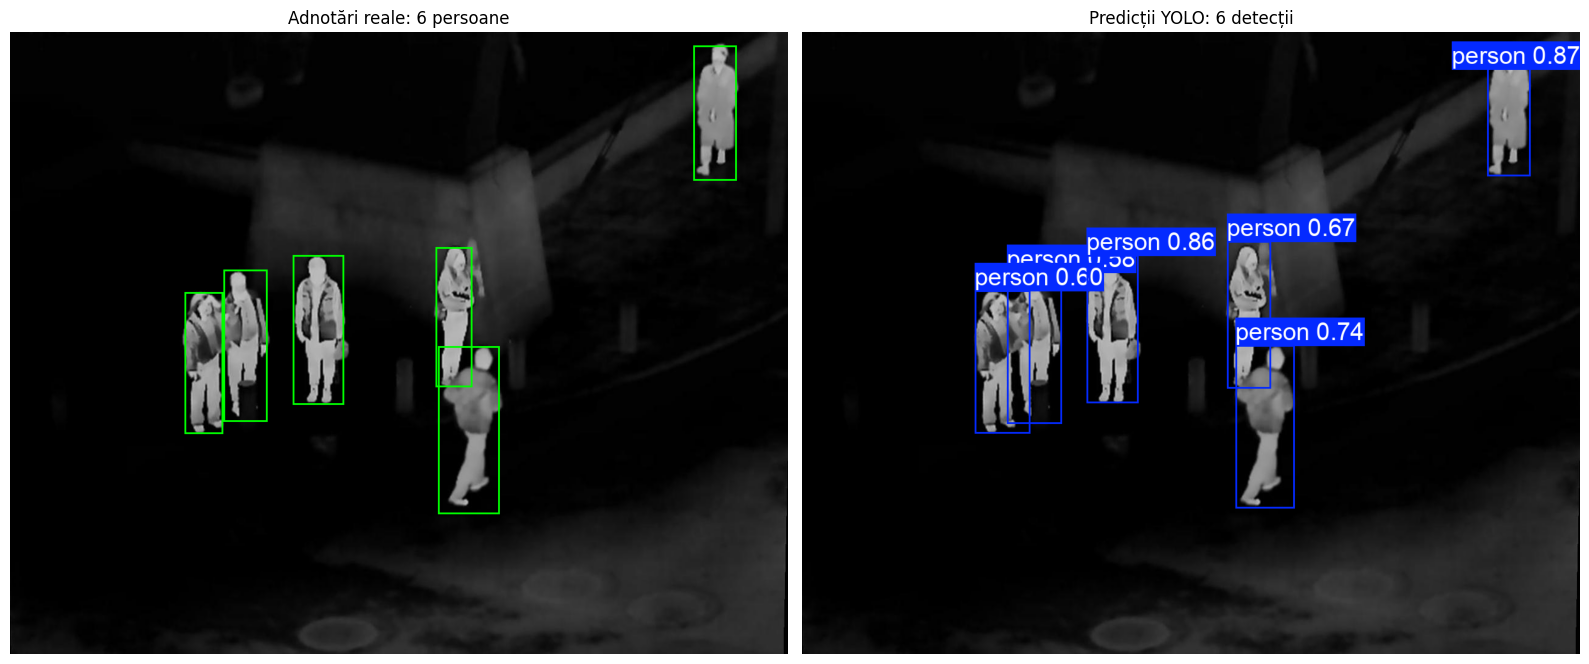

In [ ]:
imagine_yolo = rezultat.plot(pil=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(imagine_cu_bbox)
axes[0].set_title(
    f"Adnotări reale: {len(boxes_xyxy)} persoane"
)
axes[0].axis("off")

axes[1].imshow(imagine_yolo)
axes[1].set_title(
    f"Predicții YOLO: {len(rezultat.boxes)} detecții"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
predictii = []

for box in rezultat.boxes:
    coordonate = box.xyxy[0].cpu().tolist()
    scor = box.conf[0].item()

    predictii.append({
        "box": tuple(coordonate),
        "score": scor
    })

for i, predictie in enumerate(predictii, start=1):
    print(
        f"Detecția {i}: "
        f"bbox={predictie['box']}, "
        f"confidence={predictie['score']:.3f}"
    )

Detecția 1: bbox=(1127.010009765625, 17.723663330078125, 1198.594482421875, 238.08795166015625), confidence=0.868
Detecția 2: bbox=(468.78045654296875, 368.7840576171875, 553.2344360351562, 611.8986206054688), confidence=0.860
Detecția 3: bbox=(713.0244750976562, 516.6768798828125, 810.3793334960938, 784.37353515625), confidence=0.736
Detecția 4: bbox=(699.3021850585938, 345.85028076171875, 771.7080688476562, 587.3379516601562), confidence=0.665
Detecția 5: bbox=(284.2433776855469, 426.60992431640625, 375.5158996582031, 661.6727905273438), confidence=0.605
Detecția 6: bbox=(337.7706298828125, 396.7132263183594, 427.9512939453125, 645.8267822265625), confidence=0.577


## 8. Procesarea regiunilor prin Telea

Folosim implementarea existentă `cv2.inpaint(..., cv2.INPAINT_TELEA)`, cu raza 3 pixeli.
Metoda reconstruiește conținutul din mască pornind de la vecinătatea ei.
Copiem rezultatul numai în ROI, apoi verificăm explicit că restul pixelilor este identic.

Aceasta este o modificare digitală a conținutului imaginii. Nu măsurăm temperaturi și
nu demonstrăm un camuflaj fizic. Masca cuprinde dreptunghiurile GT, inclusiv fundalul din interiorul lor.


In [ ]:
import cv2
import numpy as np


def camo_telea(image, boxes_xyxy, radius=3):
    # Masca are aceeași înălțime și lățime ca imaginea.
    mask = np.zeros(image.shape[:2], dtype=np.uint8)

    for x1, y1, x2, y2 in boxes_xyxy:
        mask[y1:y2, x1:x2] = 255

    # Dacă nu există ROI-uri, păstrăm imaginea.
    if not np.any(mask):
        return image.copy()

    if np.all(mask > 0):
        raise ValueError(
            "Telea are nevoie de fundal în afara măștii."
        )

    # Reconstruim regiunile indicate de mască.
    reconstructed = cv2.inpaint(
        image,
        mask,
        radius,
        cv2.INPAINT_TELEA
    )

    # Copiem rezultatul numai în interiorul ROI-urilor.
    processed = image.copy()
    processed[mask > 0] = reconstructed[mask > 0]

    return processed

Dimensiuni original: (1024, 1280, 3)
Dimensiuni rezultat: (1024, 1280, 3)
Fundal neschimbat: True


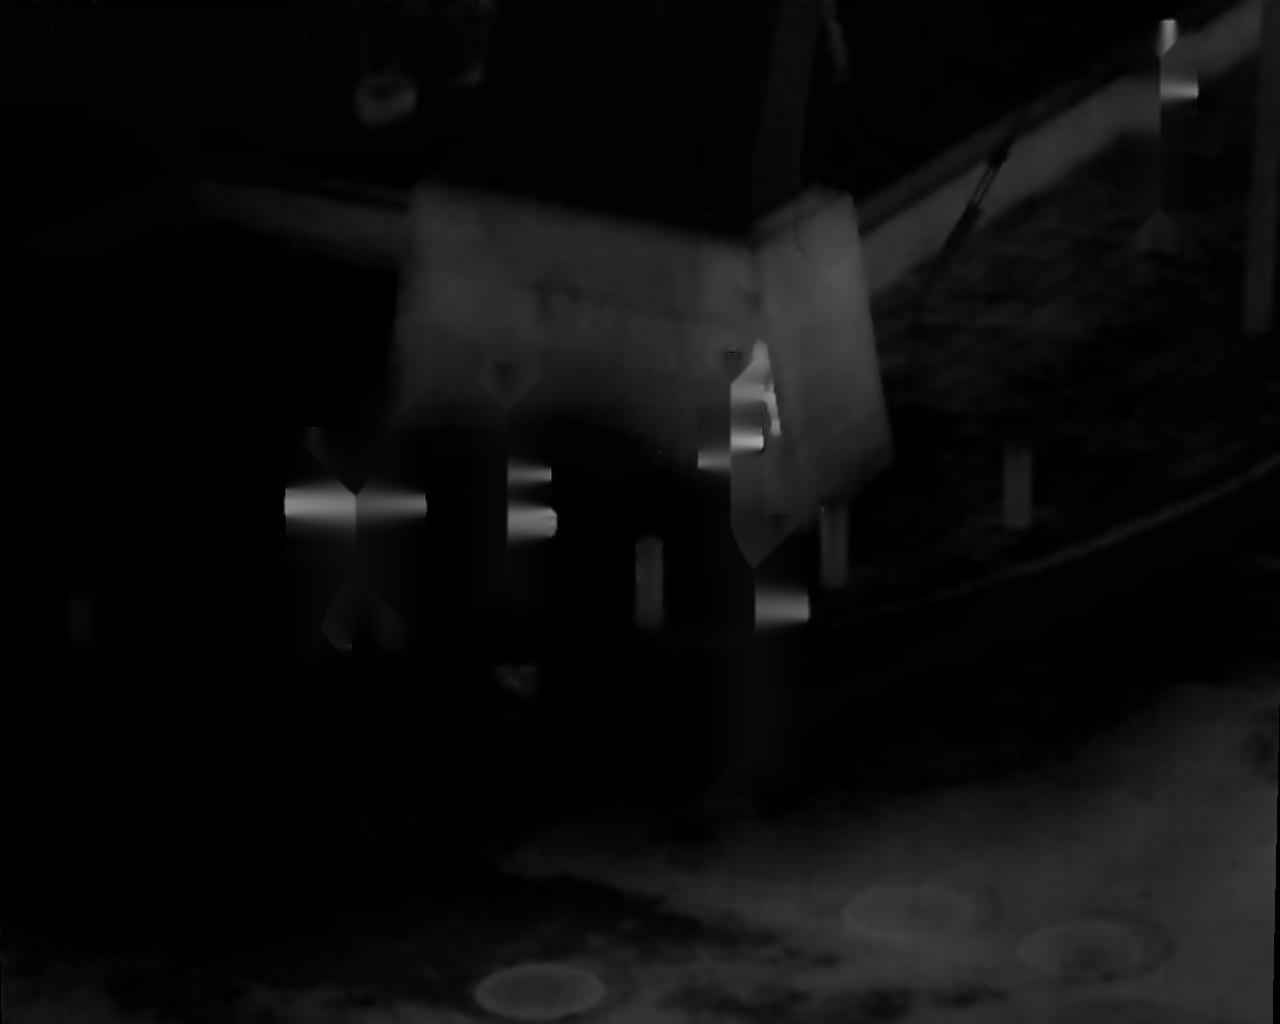

In [ ]:
# Transformăm imaginea Pillow într-o matrice NumPy.
original_np = np.array(imagine.convert("RGB"))

RAZA_TELEA = 3

telea_np = camo_telea(
    original_np,
    boxes_xyxy,
    radius=RAZA_TELEA
)

print("Dimensiuni original:", original_np.shape)
print("Dimensiuni rezultat:", telea_np.shape)

fundal_identic = np.array_equal(
    original_np[masca == 0],
    telea_np[masca == 0]
)

print("Fundal neschimbat:", fundal_identic)

display(Image.fromarray(telea_np))

## 9. Comparația înainte și după procesare

Rulăm **același model**, cu aceiași parametri, pe original și pe imaginea după Telea.
Figura cu patru panouri leagă schimbarea vizuală de răspunsul detectorului.
În exemplul `010001.jpg` din rularea păstrată sunt 6 adnotări, 6 predicții pe original și 0 după Telea.
Evaluarea corectitudinii detecțiilor se face separat, prin IoU.


In [ ]:
rezultate = model.predict(
    source=[
        Image.fromarray(original_np),
        Image.fromarray(telea_np)
    ],
    classes=[0],
    conf=CONF,
    imgsz=IMGSZ,
    iou=NMS_IOU,
    device="cpu",
    verbose=False
)

rezultat_original = rezultate[0]
rezultat_telea = rezultate[1]

print("Persoane adnotate:", len(boxes_xyxy))
print(
    "Detecții pe original:",
    len(rezultat_original.boxes)
)
print(
    "Detecții după Telea:",
    len(rezultat_telea.boxes)
)

Persoane adnotate: 6
Detecții pe original: 6
Detecții după Telea: 0


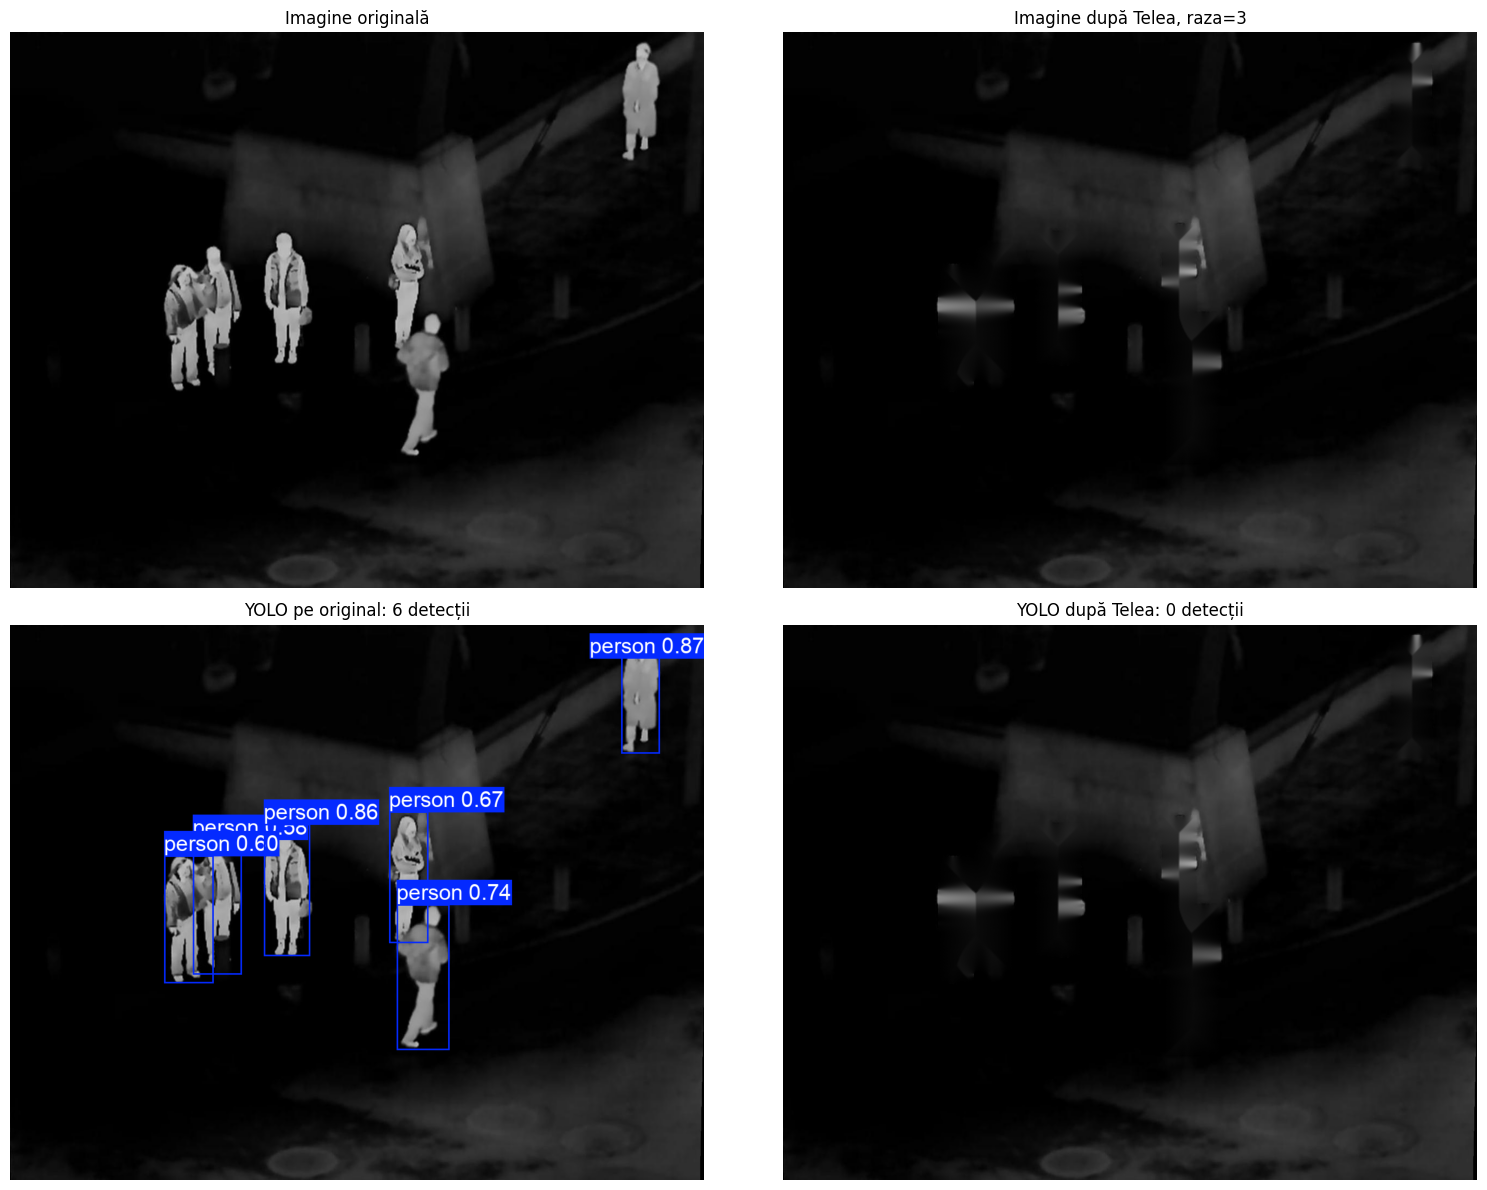

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].imshow(original_np)
axes[0, 0].set_title("Imagine originală")

axes[0, 1].imshow(telea_np)
axes[0, 1].set_title(
    f"Imagine după Telea, raza={RAZA_TELEA}"
)

axes[1, 0].imshow(
    rezultat_original.plot(pil=True)
)
axes[1, 0].set_title(
    f"YOLO pe original: "
    f"{len(rezultat_original.boxes)} detecții"
)

axes[1, 1].imshow(
    rezultat_telea.plot(pil=True)
)
axes[1, 1].set_title(
    f"YOLO după Telea: "
    f"{len(rezultat_telea.boxes)} detecții"
)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Salvarea exemplului și pregătirea exportului

Salvăm imaginea procesată și figura comparativă în `/content/PI_rezultate`.
Pentru lot vom exporta imaginile, GT, coordonatele și scorurile predicțiilor.
Astfel, evaluatorul poate calcula metricile ulterior, fără să ruleze din nou YOLO.


In [ ]:
OUT = Path("/content/PI_rezultate")
OUT.mkdir(parents=True, exist_ok=True)

nume = image_path.stem

Image.fromarray(telea_np).save(
    OUT / f"{nume}_telea.png"
)

fig.savefig(
    OUT / f"{nume}_comparatie_telea.png",
    dpi=150,
    bbox_inches="tight"
)

print("Rezultatele sunt în:", OUT)

Rezultatele sunt în: /content/PI_rezultate


In [ ]:
import csv
import json

RUN = OUT / "demo_12_imagini"
IMG_OUT = RUN / "images"

IMG_OUT.mkdir(parents=True, exist_ok=True)


def extrage_predictii(rezultat):
    predictii = []

    for box in rezultat.boxes:
        predictii.append({
            "box": box.xyxy[0].cpu().tolist(),
            "score": box.conf[0].item()
        })

    return predictii

## 11. Rularea pe cele 12 imagini

Pentru fiecare imagine citim GT, aplicăm Telea, verificăm fundalul și rulăm modelul pe perechea
original–procesat. Salvăm imagini fără dreptunghiuri desenate; evaluatorul le compară pixel cu pixel.
Orice schimbare a fundalului în afara măștii oprește rularea cu o eroare.


In [ ]:
subset_demo = list(selectie)

randuri = []
date_evaluare = []

for i, cale in enumerate(subset_demo, start=1):
    img_pil = Image.open(cale).convert("RGB")
    original = np.array(img_pil)

    cale_txt = (
        ROOT / "train" / "labels" / f"{cale.stem}.txt"
    )

    gt = citeste_bbox_yolo(
        cale_txt,
        img_pil.width,
        img_pil.height
    )

    modificat = camo_telea(
        original,
        gt,
        radius=RAZA_TELEA
    )

    # Construim masca acestei imagini.
    mask_local = np.zeros(
        original.shape[:2],
        dtype=np.uint8
    )

    for x1, y1, x2, y2 in gt:
        mask_local[y1:y2, x1:x2] = 255

    fundal_ok = np.array_equal(
        original[mask_local == 0],
        modificat[mask_local == 0]
    )

    if not fundal_ok:
        raise ValueError(f"Fundal modificat: {cale.name}")

    rez_original, rez_telea = model.predict(
        source=[
            Image.fromarray(original),
            Image.fromarray(modificat)
        ],
        classes=[0],
        conf=CONF,
        imgsz=IMGSZ,
        iou=NMS_IOU,
        device="cpu",
        verbose=False
    )

    randuri.append({
        "imagine": cale.name,
        "persoane_adnotate": len(gt),
        "detectii_original": len(rez_original.boxes),
        "detectii_telea": len(rez_telea.boxes),
        "fundal_neschimbat": bool(fundal_ok)
    })

    date_evaluare.append({
        "image_id": cale.stem,
        "source": str(cale.relative_to(ROOT)),
        "ground_truth": gt,
        "original": extrage_predictii(rez_original),
        "telea": extrage_predictii(rez_telea)
    })

    Image.fromarray(original).save(
        IMG_OUT / f"{cale.stem}_original.png"
    )

    Image.fromarray(modificat).save(
        IMG_OUT / f"{cale.stem}_telea.png"
    )

    print(
        f"{i}/{len(subset_demo)} — {cale.name}: "
        f"adnotate={len(gt)}, "
        f"original={len(rez_original.boxes)}, "
        f"Telea={len(rez_telea.boxes)}"
    )

1/12 — 160365.jpg: adnotate=3, original=0, Telea=0
2/12 — 040256.jpg: adnotate=4, original=4, Telea=0
3/12 — 010411.jpg: adnotate=2, original=1, Telea=0
4/12 — 081078.jpg: adnotate=1, original=0, Telea=0
5/12 — 080581.jpg: adnotate=4, original=3, Telea=0
6/12 — 080223.jpg: adnotate=4, original=2, Telea=0
7/12 — 050244.jpg: adnotate=5, original=4, Telea=0
8/12 — 040111.jpg: adnotate=2, original=1, Telea=0
9/12 — 170406.jpg: adnotate=1, original=0, Telea=0
10/12 — 130482.jpg: adnotate=2, original=0, Telea=0
11/12 — 030329.jpg: adnotate=3, original=2, Telea=0
12/12 — 150163.jpg: adnotate=2, original=0, Telea=0


## 12. Exportul numărătorilor și al predicțiilor

`numar_detectii.csv` conține numărătorile pe imagine. `predictii_pentru_evaluare.json`
conține GT, predicțiile cu scoruri și configurația experimentului.

În rularea păstrată: **12 imagini, 33 de persoane adnotate, 17 predicții pe originale și 0 după Telea**.
Cele 17 predicții nu sunt automat 17 persoane detectate corect; următorul pas verifică asocierea cu GT.


In [ ]:
with (RUN / "numar_detectii.csv").open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(randuri[0].keys())
    )
    writer.writeheader()
    writer.writerows(randuri)


config = {
    "dataset": (
        "sikdermdsaiful/"
        "thermal-images-for-human-detection/versions/1"
    ),
    "split": "train",
    "scop": "experiment preliminar pentru demo",
    "model": "yolov8n.pt",
    "ultralytics_version": ultralytics.__version__,
    "confidence": CONF,
    "imgsz": IMGSZ,
    "nms_iou": NMS_IOU,
    "telea_radius": RAZA_TELEA,
    "sample_seed": 42
}

pachet = {
    "config": config,
    "images": date_evaluare
}

(RUN / "predictii_pentru_evaluare.json").write_text(
    json.dumps(pachet, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Imagini procesate:", len(randuri))
print(
    "Total persoane adnotate:",
    sum(r["persoane_adnotate"] for r in randuri)
)
print(
    "Total detecții pe originale:",
    sum(r["detectii_original"] for r in randuri)
)
print(
    "Total detecții după Telea:",
    sum(r["detectii_telea"] for r in randuri)
)

Imagini procesate: 12
Total persoane adnotate: 33
Total detecții pe originale: 17
Total detecții după Telea: 0


## 13. Descărcarea arhivei rezultatelor

Descărcăm `PI_rezultate_preliminare.zip`. Păstrăm arhiva: conține datele necesare pentru
recalcularea metricilor, chiar dacă sesiunea Colab se închide.
Continuăm apoi cu evaluarea; tabelul final nu este încă produs în această etapă.


In [ ]:
import shutil
from google.colab import files

arhiva = shutil.make_archive(
    "/content/PI_rezultate_preliminare",
    "zip",
    root_dir=OUT
)

files.download(arhiva)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Evaluarea detecțiilor și a modificării imaginii

Instalăm `scikit-image` pentru SSIM. Evaluatorul de mai jos folosește predicțiile deja exportate.

IoU este raportul dintre aria intersecției și aria reuniunii a două dreptunghiuri.
Procesăm predicțiile în ordinea descrescătoare a scorului. Fiecare predicție este asociată
cu cel mai potrivit GT încă neasociat, dacă **IoU ≥ 0,50**. Un GT poate produce un singur TP.

| Termen | Înțeles |
|---|---|
| TP | Predicție asociată corect unei persoane GT |
| FP | Predicție fără o asociere validă, inclusiv o dublură |
| FN | Persoană GT rămasă fără o predicție corectă |

$$
\mathrm{Precision}=\frac{TP}{TP+FP},\qquad
\mathrm{Recall}=\frac{TP}{TP+FN}.
$$

Dacă nu există predicții, Precision este **nedefinită** (`0/0`), nu 0% sau 100%.
După Telea, FN și Recall sunt raportate la țintele originale: conținutul lor a fost modificat sau eliminat digital.
Nu calculăm mAP din predicțiile deja filtrate la confidence 0,25.


In [ ]:
%pip install -q scikit-image

### 14.1. Crearea evaluatorului în sesiunea Colab

Rulăm următoarea celulă pentru a crea `/content/evaluator_referinta.py`.
`%%writefile` scrie codul din celulă într-un fișier; evaluarea propriu-zisă se execută în celula următoare.
Nu mai este necesară încărcarea manuală a acestui script.

Pentru explicația orală urmărim trei funcții: `evaluate` asociază predicțiile cu GT,
`make_mask` reface masca, iar `quality_metrics` verifică fundalul și măsoară modificarea imaginii.


In [ ]:
%%writefile /content/evaluator_referinta.py
"""Evaluare a predicțiilor exportate de notebook, fără rerularea YOLO.

Exemplu în terminal:
python evaluator_referinta.py PI_rezultate_preliminare.zip --out evaluare

În Colab sunt necesare numpy, Pillow și scikit-image.
Precision/Recall se calculează la un prag IoU fix, pe predicțiile deja filtrate.
"""
import argparse
import csv
import hashlib
import io
import json
import math
from pathlib import Path
from zipfile import ZipFile

import numpy as np
from PIL import Image
from skimage.metrics import structural_similarity


def iou(box_a, box_b):
    """Intersecție / reuniune. Coordonatele xyxy folosesc limite exclusive."""
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def evaluate(predictions, ground_truth, iou_threshold=0.5):
    """Asociere unu-la-unu, cu predicțiile ordonate descrescător după score.

    Fiecare persoană reală poate contribui la un singur TP.
    Valorile nedefinite, inclusiv Precision pentru zero predicții, sunt None.
    """
    available = set(range(len(ground_truth)))
    matched_ious = []
    details = []
    ordered = sorted(enumerate(predictions), key=lambda pair: pair[1]['score'], reverse=True)
    for prediction_index, prediction in ordered:
        best = max(available, key=lambda j: iou(prediction['box'], ground_truth[j]), default=None)
        best_iou = iou(prediction['box'], ground_truth[best]) if best is not None else 0.0
        is_tp = best is not None and best_iou >= iou_threshold
        if is_tp:
            available.remove(best)
            matched_ious.append(best_iou)
        details.append({
            'prediction_index': prediction_index,
            'score': prediction['score'],
            'status': 'TP' if is_tp else 'FP',
            'matched_gt_index': best if is_tp else None,
            'matched_iou': best_iou if is_tp else None,
            'best_iou_any_gt': max((iou(prediction['box'], gt) for gt in ground_truth), default=0.0),
        })
    tp = len(matched_ious)
    fp = len(predictions) - tp
    fn = len(ground_truth) - tp
    return {
        'tp': tp, 'fp': fp, 'fn': fn,
        'precision': tp / (tp + fp) if tp + fp else None,
        'recall': tp / (tp + fn) if tp + fn else None,
        'mean_iou_matched': float(np.mean(matched_ious)) if matched_ious else None,
        'matched_ious': matched_ious, 'details': details,
    }


def make_mask(shape, boxes):
    mask = np.zeros(shape, dtype=bool)
    height, width = shape
    for x1, y1, x2, y2 in boxes:
        if not all(float(v).is_integer() for v in (x1, y1, x2, y2)):
            raise ValueError('Măștile exportate trebuie să aibă coordonate întregi.')
        x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))
        if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
            raise ValueError(f'BBox invalid: {(x1,y1,x2,y2)}')
        mask[y1:y2, x1:x2] = True
    return mask


def quality_metrics(original_rgb, modified_rgb, mask):
    if original_rgb.shape != modified_rgb.shape:
        raise ValueError('Imaginile trebuie să aibă aceleași dimensiuni.')
    background_changed = int(np.count_nonzero(np.any(original_rgb != modified_rgb, axis=2) & ~mask))
    original = np.asarray(Image.fromarray(original_rgb).convert('L'))
    modified = np.asarray(Image.fromarray(modified_rgb).convert('L'))
    window = min(7, *original.shape)
    window -= 1 - window % 2
    global_ssim, ssim_map = structural_similarity(original, modified, data_range=255, win_size=window, full=True)
    if mask.any():
        mse = float(np.mean((original.astype(np.float64)[mask] - modified.astype(np.float64)[mask]) ** 2))
        psnr = math.inf if mse == 0 else 10 * math.log10(255 ** 2 / mse)
        roi_ssim = float(ssim_map[mask].mean())
    else:
        psnr = roi_ssim = None
    return {'roi_pixels': int(mask.sum()), 'background_changed_pixels': background_changed,
            'psnr_roi_db': psnr, 'ssim_roi_map': roi_ssim, 'ssim_global': float(global_ssim)}


def write_csv(path, rows):
    with path.open('w', encoding='utf-8-sig', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('archive', type=Path)
    parser.add_argument('--out', type=Path, default=Path('evaluare_preliminara'))
    parser.add_argument('--iou', type=float, default=0.5)
    args = parser.parse_args()
    if not 0 < args.iou <= 1:
        parser.error('IoU trebuie să fie în intervalul (0,1].')
    args.out.mkdir(parents=True, exist_ok=True)
    prefix = 'demo_12_imagini'
    rows = []
    diagnostics = []
    with ZipFile(args.archive) as archive:
        if archive.testzip() is not None:
            raise ValueError('Arhiva are fișiere cu CRC invalid.')
        source = json.loads(archive.read(f'{prefix}/predictii_pentru_evaluare.json'))
        counts = list(csv.DictReader(io.StringIO(archive.read(f'{prefix}/numar_detectii.csv').decode('utf-8-sig'))))
        counts_by_id = {Path(row['imagine']).stem: row for row in counts}
        ids = [item['image_id'] for item in source['images']]
        if len(ids) != len(set(ids)) or set(ids) != set(counts_by_id):
            raise ValueError('Listele CSV și JSON diferă sau conțin duplicate.')
        for item in source['images']:
            image_id = item['image_id']
            original = np.asarray(Image.open(io.BytesIO(archive.read(f'{prefix}/images/{image_id}_original.png'))).convert('RGB'))
            modified = np.asarray(Image.open(io.BytesIO(archive.read(f'{prefix}/images/{image_id}_telea.png'))).convert('RGB'))
            mask = make_mask(original.shape[:2], item['ground_truth'])
            q = quality_metrics(original, modified, mask)
            if q['background_changed_pixels'] != 0:
                raise ValueError(f'Fundal modificat în {image_id}.')
            diagnostic = {'image_id': image_id, 'quality': q}
            for method in ('original', 'telea'):
                expected = int(counts_by_id[image_id][f'detectii_{method}'])
                if expected != len(item[method]) or int(counts_by_id[image_id]['persoane_adnotate']) != len(item['ground_truth']):
                    raise ValueError(f'Numere CSV/JSON inconsistente în {image_id}.')
                for prediction in item[method]:
                    if not math.isfinite(prediction['score']) or not 0 <= prediction['score'] <= 1:
                        raise ValueError('Scor de predicție invalid.')
                result = evaluate(item[method], item['ground_truth'], args.iou)
                quality = q if method == 'telea' else {'roi_pixels': int(mask.sum()), 'background_changed_pixels': 0, 'psnr_roi_db': math.inf, 'ssim_roi_map': 1.0, 'ssim_global': 1.0}
                rows.append({'image_id': image_id, 'method': method, 'n_gt': len(item['ground_truth']), 'n_predictions': len(item[method]),
                             **{key: result[key] for key in ('tp', 'fp', 'fn', 'precision', 'recall', 'mean_iou_matched')}, **quality})
                diagnostic[method] = result
            diagnostics.append(diagnostic)
    summaries = []
    for method in ('original', 'telea'):
        selected = [row for row in rows if row['method'] == method]
        tp, fp, fn = (sum(row[key] for row in selected) for key in ('tp', 'fp', 'fn'))
        matched = [value for item in diagnostics for value in item[method]['matched_ious']]
        summaries.append({'method': method, 'n_images': len(selected), 'n_gt': sum(row['n_gt'] for row in selected),
                          'n_predictions': sum(row['n_predictions'] for row in selected), 'tp': tp, 'fp': fp, 'fn': fn,
                          'precision': tp/(tp+fp) if tp+fp else None, 'recall': tp/(tp+fn) if tp+fn else None,
                          'n_matched': len(matched), 'mean_iou_matched': float(np.mean(matched)) if matched else None,
                          'mean_psnr_roi_db': float(np.mean([row['psnr_roi_db'] for row in selected])),
                          'mean_ssim_roi_map': float(np.mean([row['ssim_roi_map'] for row in selected])),
                          'mean_ssim_global': float(np.mean([row['ssim_global'] for row in selected])),
                          'background_changed_pixels': sum(row['background_changed_pixels'] for row in selected)})
    write_csv(args.out / 'evaluare_pe_imagine.csv', rows)
    write_csv(args.out / 'sumar_evaluare.csv', summaries)
    # JSON strict: PSNR infinit pentru identitate se reprezintă prin text.
    def clean(value):
        if isinstance(value, float) and not math.isfinite(value):
            return '+inf' if value > 0 else None
        if isinstance(value, dict): return {key: clean(v) for key, v in value.items()}
        if isinstance(value, list): return [clean(v) for v in value]
        return value
    import PIL, skimage
    metadata = {'source_archive_sha256': hashlib.sha256(args.archive.read_bytes()).hexdigest(),
                'config': source['config'], 'matching_iou': args.iou,
                'quality_convention': '8-bit luminance; PSNR on union ROI; mean SSIM map at ROI centres; win_size=7; data_range=255; arithmetic mean of image scores.',
                'versions_evaluation': {'numpy': np.__version__, 'Pillow': PIL.__version__, 'scikit-image': skimage.__version__},
                'summary': summaries, 'images': diagnostics,
                'limitations': ['12 images from train, development subset.', 'Telea removes digital content; post-edit recall refers to original targets.', 'mAP not calculated from predictions already filtered at confidence 0.25.']}
    (args.out / 'evaluare_detaliata.json').write_text(json.dumps(clean(metadata), indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    print(json.dumps(clean(summaries), indent=2, ensure_ascii=False))


if __name__ == '__main__':
    main()


Writing /content/evaluator_referinta.py


### 14.2. Rularea evaluatorului

Se produc două CSV-uri și un JSON detaliat în `/content/PI_evaluare`.


In [ ]:
!python /content/evaluator_referinta.py /content/PI_rezultate_preliminare.zip --out /content/PI_evaluare

[
  {
    "method": "original",
    "n_images": 12,
    "n_gt": 33,
    "n_predictions": 17,
    "tp": 13,
    "fp": 4,
    "fn": 20,
    "precision": 0.7647058823529411,
    "recall": 0.3939393939393939,
    "n_matched": 13,
    "mean_iou_matched": 0.8035922326014527,
    "mean_psnr_roi_db": "+inf",
    "mean_ssim_roi_map": 1.0,
    "mean_ssim_global": 1.0,
    "background_changed_pixels": 0
  },
  {
    "method": "telea",
    "n_images": 12,
    "n_gt": 33,
    "n_predictions": 0,
    "tp": 0,
    "fp": 0,
    "fn": 33,
    "precision": null,
    "recall": 0.0,
    "n_matched": 0,
    "mean_iou_matched": null,
    "mean_psnr_roi_db": 11.089254514457728,
    "mean_ssim_roi_map": 0.42841136697456167,
    "mean_ssim_global": 0.9737441090801493,
    "background_changed_pixels": 0
  }
]


## 15. Tabelul final și interpretarea metricilor

Celula de mai jos citește `/content/PI_evaluare/sumar_evaluare.csv` și afișează rezultatele calculate,
fără valori introduse manual.

PSNR și SSIM compară originalul cu imaginea procesată pe luminanță de 8 biți (`data_range=255`).
PSNR se calculează pe reuniunea ROI. SSIM în ROI este media hărții SSIM în punctele din mască;
fereastra locală de 7×7 poate include și vecini din afara ei. Raportăm media aritmetică
a scorurilor celor 12 imagini, separat de metricile globale de detecție.

Un SSIM global mare poate apărea deoarece fundalul ocupă mult din imagine și rămâne identic.
PSNR și SSIM arată cât s-a schimbat imaginea; singure nu măsoară performanța detectorului.


In [ ]:
import csv
import math
from pathlib import Path
from IPython.display import Markdown, display

cale_sumar = Path("/content/PI_evaluare/sumar_evaluare.csv")
if not cale_sumar.is_file():
    raise FileNotFoundError("Rulează mai întâi celula de evaluare din secțiunea 14.")

with cale_sumar.open(encoding="utf-8-sig", newline="") as f:
    sumare = list(csv.DictReader(f))

def procent(valoare):
    if valoare == "":
        return "nedefinită"
    return f"{100 * float(valoare):.2f}%".replace(".", ",")

def valoare_metric(valoare, zecimale=3):
    if valoare == "":
        return "nedefinită"
    numar = float(valoare)
    if math.isinf(numar):
        return "∞"
    return f"{numar:.{zecimale}f}".replace(".", ",")

linii = [
    "| Variantă | Imagini | GT | Predicții | TP | FP | FN | Precision | Recall |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|"
]
for r in sumare:
    nume_metoda = "Original" if r["method"] == "original" else "După Telea"
    valori = [nume_metoda] + [r[k] for k in ("n_images", "n_gt", "n_predictions", "tp", "fp", "fn")]
    valori += [procent(r["precision"]), procent(r["recall"])]
    linii.append("| " + " | ".join(valori) + " |")

display(Markdown("\n".join(linii)))

r_telea = next(r for r in sumare if r["method"] == "telea")
display(Markdown(
    "**Modificarea imaginii după Telea:**\n\n"
    f"- PSNR mediu în ROI: **{valoare_metric(r_telea['mean_psnr_roi_db'], 2)} dB**\n"
    f"- SSIM mediu în ROI: **{valoare_metric(r_telea['mean_ssim_roi_map'])}**\n"
    f"- SSIM global mediu: **{valoare_metric(r_telea['mean_ssim_global'])}**\n"
    f"- Pixeli modificați în afara măștii: **{r_telea['background_changed_pixels']}**"
))


| Variantă | Imagini | GT | Predicții | TP | FP | FN | Precision | Recall |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Original | 12 | 33 | 17 | 13 | 4 | 20 | 76,47% | 39,39% |
| După Telea | 12 | 33 | 0 | 0 | 0 | 33 | nedefinită | 0,00% |

**Modificarea imaginii după Telea:**

- PSNR mediu în ROI: **11,09 dB**
- SSIM mediu în ROI: **0,428**
- SSIM global mediu: **0,974**
- Pixeli modificați în afara măștii: **0**

## 16. Ce prezentăm la următoarea ascultare

**Concluzia susținută de acest experiment:** prototipul încarcă datele, modifică exclusiv ROI
și permite compararea reproductibilă a răspunsului aceluiași detector pe original și după Telea.
Pe cele 12 exemple păstrate dispar predicțiile după procesare. Lotul este mic, din `train`,
iar modelul nu este adaptat pe termic; nu generalizăm rezultatul la întregul dataset sau la alte modele.
În plus, pe unele imagini detectorul nu găsea persoane nici înainte de modificare.

### Demonstrația, în ordine

1. Arătăm o imagine cu GT și explicăm formatul etichetelor.
2. Arătăm masca și spunem că provine din adnotări.
3. Arătăm figura original–Telea și predicțiile aceluiași YOLO.
4. Arătăm lotul de 12 imagini și tabelul Precision/Recall; explicăm TP, FP și FN.
5. Menționăm verificarea fundalului, limitele experimentului și pașii ulteriori din PPT.

Pregătim sesiunea înainte de ascultare și păstrăm notebook-ul cu ieșiri, arhiva și PPT-ul
ca materiale disponibile și dacă nu putem descărca din nou datele în timpul prezentării.

### Împărțirea pregătirii, cu lucru independent

| Persoană | Ce pregătește acum | Rezultat concret |
|---|---|---|
| Daria | Datele, GT, masca, YOLO, Telea și figura comparativă | Poate rula și explica demonstrația pe o imagine |
| Ionela | Evaluatorul, IoU, TP/FP/FN, Precision/Recall și SSIM/PSNR | Poate explica tabelul și un exemplu de asociere |
| Împreună | Alinierea PPT-ului cu rezultatele și o repetiție | Prezentare coerentă, cu limitările spuse explicit |

Pentru lucrul în paralel, Daria produce arhiva, iar Ionela poate folosi evaluatorul pe acea arhivă
fără să descarce datasetul sau să ruleze YOLO. Validarea completă a etichetelor, separarea `train/val`,
adaptarea detectorului pe termic și comparațiile cu alte metode rămân pași de dezvoltare;
nu îi prezentăm drept funcționalități deja implementate aici.

### Sursele componentelor reutilizate

- [Datasetul Kaggle](https://www.kaggle.com/datasets/sikdermdsaiful/thermal-images-for-human-detection)
- [KaggleHub: descărcarea unei versiuni de dataset](https://github.com/Kaggle/kagglehub#download-dataset)
- [Ultralytics: documentație](https://docs.ultralytics.com/) · [versiunea folosită, 8.4.197](https://pypi.org/project/ultralytics/8.4.197/)
- [OpenCV: inpainting](https://docs.opencv.org/4.x/d7/d8b/group__photo__inpaint.html)
- [scikit-image: metrici](https://scikit-image.org/docs/stable/api/skimage.metrics.html)
- [IPython: `%%writefile`](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-writefile)
